# Step and layered water: tanh / erf optical references

RuO2 on TiO2 with water following the Poisson terraces. There are two physical
families: **step**, an erf onset with an optional adsorbed Gaussian, and
**layered**, progressively broadened molecular layers. Both use independent
O + 2H form factors. The four length parameters are fractions of the normal
cell height; the example converts from Angstrom explicitly.

For the step, `optical_reference="tanh"` composes analytic Epstein interface
amplitudes for s polarization. Sharp/tanh fitting uses constant-medium DWBA
channels and analytic water transforms: no profile slicing or quadrature.
The whole layered stack uses one damped Hosemann expression per channel.
`"erf"` explicitly selects full continuous numerical confirmation.
**Switching reference keeps physical densities and form factors identical**,
but also tests the constant-medium approximation. Sharp optics supports s/p;
analytic tanh requires s and never silently starts an ODE solver.

The step midpoint is **3.0 Angstrom above each local terrace**, with intrinsic
RMS width 1.0 Angstrom. `step_A0 = 0.8` adds 0.8 adsorbed water molecules per
lateral cell using the existing one-layer offset rule; set it to zero to remove
adsorption. The midpoint is an illustrative fit starting value, not a measured
adsorption height or a hard empty gap. See [interfacial water on RuO2](https://www.nature.com/articles/s41467-026-70737-0)
and the discussion of terrace averaging in [Kawaguchi et al.](https://arxiv.org/pdf/2002.11521).

For layered water, 3.0 Angstrom locates the first Gaussian center. Its spacing,
initial width and cumulative broadening are 2.8, 1.0 and 1.4 Angstrom, with first-layer
relative weight 0.8. That weight has different units/meaning from step A0.

Set `include_confirmation = False` to omit erf or `include_layered = False`
to omit layering. All CTRs use s polarization, equal local glancing angles and
one common normalization plane in water. The critical markers use the nominal
lossless substrate edge,
$\alpha_c=\arccos[\mathrm{Re}(n_{\mathrm{TiO_2}})/\mathrm{Re}(n_{\mathrm{ambient}})]$.
Absorption and the finite film round and reshape that edge.


In [1]:
%matplotlib inline
from pathlib import Path
import copy
import time
import sys
import numpy as np
import matplotlib.pyplot as plt

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "orgui").is_dir())
sys.path.insert(0, str(root))
from orgui.datautils.xrayutils.CTRcalc import SXRDCrystal
from orgui.datautils.xrayutils.CTRuc import WaterModel
from orgui.datautils.xrayutils.CTRfilm import PoissonSurface

dry = SXRDCrystal.fromFile(root / "examples/CTR/RuO2_TiO2_Poisson_etching.xtal")
surface = next(c for c in dry.uc_surface_list if isinstance(c, PoissonSurface))
surface.basis[1] = 0.15  # smoother terraces; mean dissolution remains six layers
energy = dry.uc_bulk._E

step_A0 = 0.8  # adsorbed molecules per lateral cell; zero disables adsorption
water_onset_A = 3.0  # continuum midpoint above each terrace; fit starting value

def water_profile(kind):
    """Construct intrinsic water with lengths converted from Å to fractions."""
    cell = dry.uc_bulk
    height = cell.volume / cell.uc_area
    family = "layered" if kind == "layered" else "step"
    reference = "sharp" if kind == "layered" else kind
    water = WaterModel(cell.a.copy(), np.rad2deg(cell.alpha), family,
                       optical_reference=reference, name="water")
    water.setWaterParameters(water_onset_A/height, 2.8/height, 1.0/height, 1.4/height, 0.8 if kind == "layered" else step_A0)
    water.setEnergy(energy)
    np.testing.assert_allclose(water.basis[0]*height, water_onset_A)
    return water

include_confirmation = True
include_layered = True
models = {"dry": dry}
profiles = [("terrace tanh", "tanh")]
if include_confirmation:
    profiles += [("terrace erf", "erf")]
if include_layered:
    profiles += [("terrace layered", "layered")]
for label, kind in profiles:
    model = copy.deepcopy(dry)
    next(c for c in model.uc_surface_list if isinstance(c, PoissonSurface)).attach_water(water_profile(kind))
    models[label] = model


In [2]:
L = np.r_[np.geomspace(0.004, 0.12, 35), np.linspace(0.13, 3.0, 181)]
results = {}
for label, model in models.items():
    model.dwba.set_ctr_geometry(equal_angles=True, rods=[(0.0, 0.0)])
    start = time.perf_counter()
    prepared = model.dwba.prepare(np.zeros_like(L), np.zeros_like(L), L)
    optics_time = time.perf_counter() - start
    result = model.dwba.evaluate_prepared(prepared)
    cold = time.perf_counter() - start
    results[label] = result
    start = time.perf_counter()
    repeated = model.dwba.evaluate_prepared(prepared)
    np.testing.assert_array_equal(result.reflectivity, repeated.reflectivity)
    solver = getattr(prepared.field_i, "solver", "analytic interfaces / constant media")
    print(f"{label}: {solver}; optics {optics_time:.2f} s, full {cold:.2f} s, reused {time.perf_counter()-start:.2f} s")

# Reflection amplitudes depend on their phase origin in absorbing water.
origins = {name: float(np.atleast_1d(r.prepared.field_i.z_reference)[0]) for name, r in results.items()}
common_plane = max(origins.values())
amplitudes = {}
for name, result in results.items():
    p = result.prepared
    phase = np.exp(-1j * p.k0 * p.reference.n[0] * (np.sin(p.alpha_i) + np.sin(p.alpha_f)) * (common_plane - origins[name]))
    amplitudes[name] = result.total_amplitude * phase
reflectivity = {name: abs(value)**2 for name, value in amplitudes.items()}
if include_confirmation:
    tanh, erf = reflectivity["terrace tanh"], reflectivity["terrace erf"]
    mask = erf > 1e-10  # avoid reporting divergent ratios at deep minima
    print(f"Tanh/erf: max absolute R difference {max(abs(tanh-erf)):.3g}; max relative above R=1e-10 {max(abs(tanh[mask]/erf[mask]-1)):.2%}")
    # Tighten Maxwell tolerance on selected angles before trusting confirmation.
    p = results["terrace erf"].prepared
    angles = p.field_i.alpha[::12]
    normal = p.reference.continuous.solve(angles, "s")
    tight = p.reference.continuous.solve(angles, "s", rtol=2e-12)
    print(f"Erf convergence: max change in complex reference r {max(abs(normal.r_S-tight.r_S)):.3g}")


dry: analytic interfaces / constant media; optics 0.05 s, full 0.14 s, reused 0.09 s


terrace tanh: analytic interfaces / constant media; optics 0.06 s, full 0.20 s, reused 0.14 s


terrace erf: numerical; optics 3.34 s, full 11.47 s, reused 0.70 s


terrace layered: analytic interfaces / constant media; optics 0.07 s, full 0.28 s, reused 0.13 s
Tanh/erf: max absolute R difference 1.02e-05; max relative above R=1e-10 0.05%


Erf convergence: max change in complex reference r 1.72e-08


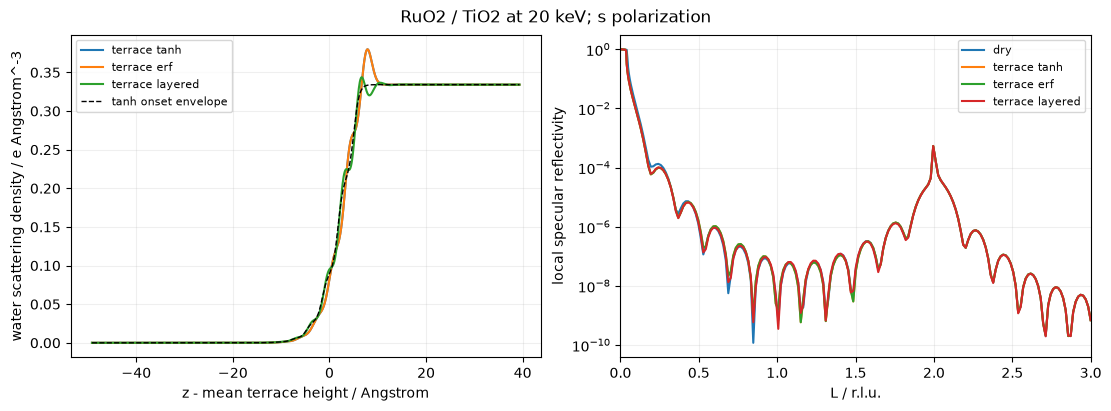

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
dry.apply_stacking()
heights, probabilities, _ = surface.terrace_distribution()
mean_height = heights @ probabilities
# Include two substrate repeats and eight Angstrom beyond all water tails.
profile_bounds = (-2*dry.uc_bulk.volume/dry.uc_bulk.uc_area,
                  max(next(c for c in model.uc_surface_list if isinstance(c, PoissonSurface))
                      .water.transition_extent()[1]
                      for name, model in models.items() if name != "dry") + 8.)
relative_bounds = np.asarray(profile_bounds) - mean_height
z = np.linspace(*profile_bounds, 1401)
for label, model in models.items():
    axes[1].semilogy(L, reflectivity[label], label=label)
    if label == "dry":
        continue
    water = next(c for c in model.uc_surface_list if isinstance(c, PoissonSurface)).water
    axes[0].plot(z-mean_height, water.zDensity_G(z, 0., 0.).real, label=label)
spec = results["terrace tanh"].prepared.reference.continuous
axes[0].plot(z-mean_height, spec.reference_density(z)[spec.water_index].real, "k--", lw=1, label="tanh onset envelope")
axes[0].set(xlabel="z - mean terrace height / Angstrom", ylabel="water scattering density / e Angstrom^-3")
axes[1].set(xlabel="L / r.l.u.", ylabel="local specular reflectivity", xlim=(0, 3))
for ax in axes:
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
fig.suptitle(f"RuO2 / TiO2 at {energy/1000:g} keV; s polarization")
plt.show()


## Refractive-index decomposition

At $h=k=0$, use the laterally averaged atomistic scattering density (including water) to form
$$n(z)=1-C\rho_f(z),\qquad n_0(z)=\sqrt{\varepsilon_0(z)},\qquad \Delta n(z)=n(z)-n_0(z),\quad C=\frac{2\pi r_e}{k_0^2}.$$
For tanh, $n_0$ is the **onset-only reference envelope**; effective interface coefficients and constant-medium channels are used in the calculation. It is not a globally solved overlapping-tanh profile. For erf, it is the full numerically solved continuous reference. This example uses fully crystalline solids; $\Delta n$ includes atomic layering and any water/reference residual. The index convention is $n=1-\delta-i\beta$.

The left panels show $1-\mathrm{Re}(n)$ and $-\mathrm{Im}(n)$, with the corresponding $n_0$ curves. The right panels show the **signed** $\mathrm{Re}(\Delta n)$ and $\mathrm{Im}(\Delta n)$. All values are dimensionless, scaled by $10^6$ (ppm). The depth window includes the TiO2 substrate, RuO2 film and water plateau; the critical-angle zoom follows below.


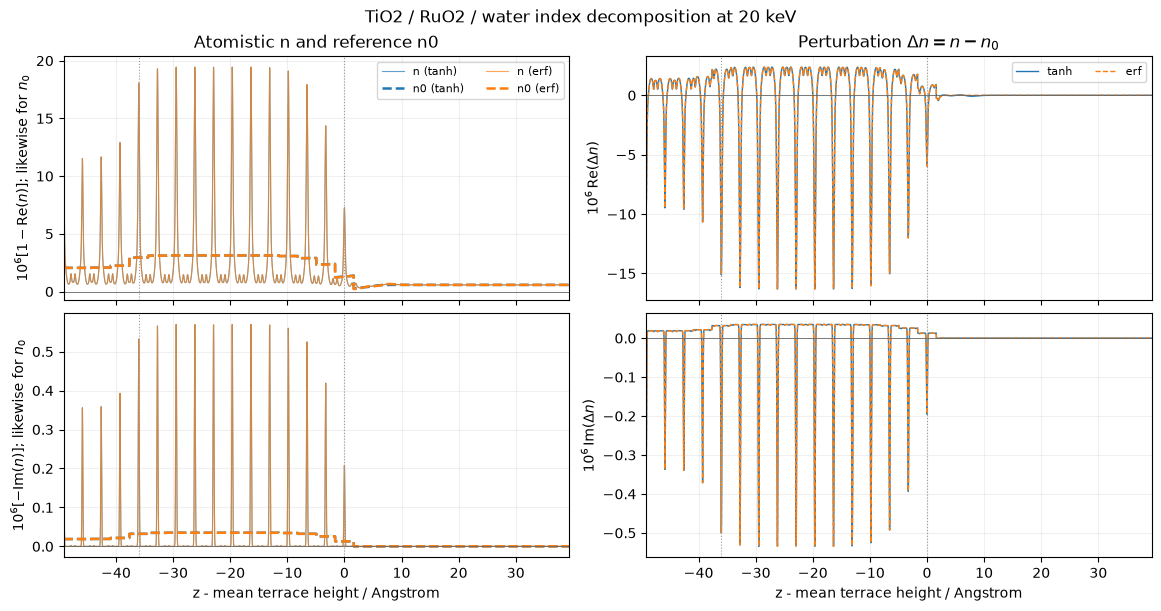

In [4]:
# Physical atomistic index versus the actual DWBA reference (film/water region).
z_index = np.linspace(*profile_bounds, 7001)
index_components = {}
fig_index, index_axes = plt.subplots(2, 2, figsize=(11.5, 6), sharex=True, constrained_layout=True)
for name, color in [("terrace tanh", "tab:blue"), ("terrace erf", "tab:orange")]:
    if name not in models:
        continue
    p = results[name].prepared
    spec = p.reference.continuous
    scale = 2 * np.pi * 2.8179403262e-5 / p.k0**2  # r_e in Angstrom
    rho = models[name].zDensity_G(z_index, 0., 0.)  # electrons / Angstrom^3
    n = 1 - scale * rho
    n0 = np.sqrt(spec.epsilon(z_index))
    delta_n = n - n0
    np.testing.assert_allclose(n, n0 + delta_n, rtol=0., atol=3e-16)
    np.testing.assert_allclose(n0, 1-scale*spec.reference_density(z_index).sum(axis=0), rtol=0., atol=5e-16)
    assert np.all(np.isfinite(n)) and np.all(np.isfinite(n0))
    index_components[name] = (n, n0, delta_n)
    label = name.removeprefix("terrace ")
    x = z_index - mean_height
    index_axes[0, 0].plot(x, 1e6*(1-n.real), color=color, lw=0.8, alpha=0.7, label=f"n ({label})")
    index_axes[0, 0].plot(x, 1e6*(1-n0.real), color=color, ls="--", lw=1.8, label=f"n0 ({label})")
    index_axes[1, 0].plot(x, -1e6*n.imag, color=color, lw=0.8, alpha=0.7)
    index_axes[1, 0].plot(x, -1e6*n0.imag, color=color, ls="--", lw=1.8)
    style = "--" if label == "erf" else "-"
    index_axes[0, 1].plot(x, 1e6*delta_n.real, color=color, ls=style, lw=1., label=label)
    index_axes[1, 1].plot(x, 1e6*delta_n.imag, color=color, ls=style, lw=1.)
index_axes[0, 0].set(title="Atomistic n and reference n0", ylabel=r"$10^6[1-\mathrm{Re}(n)]$; likewise for $n_0$")
index_axes[1, 0].set(ylabel=r"$10^6[-\mathrm{Im}(n)]$; likewise for $n_0$")
index_axes[0, 1].set(title=r"Perturbation $\Delta n=n-n_0$", ylabel=r"$10^6\,\mathrm{Re}(\Delta n)$")
index_axes[1, 1].set(ylabel=r"$10^6\,\mathrm{Im}(\Delta n)$")
for ax in index_axes.flat:
    ax.axhline(0, color="0.4", lw=0.6)
    ax.axvline(0, color="0.6", ls=":", lw=0.8)
    ax.grid(alpha=0.18)
    ax.set_xlim(*relative_bounds)
    ax.axvline(-mean_height, color="0.6", ls=":", lw=0.8)
for ax in index_axes[-1]:
    ax.set_xlabel("z - mean terrace height / Angstrom")
for ax in index_axes[0]:
    ax.legend(fontsize=8, ncol=2)
fig_index.suptitle(f"TiO2 / RuO2 / water index decomposition at {energy/1000:g} keV")
plt.show()


## Substrate, film and water plateau

This full-depth view shows the **current reference construction**, without changing the model. The dashed vertical line is the mean intrinsic water midpoint, 3.0 Angstrom above the mean terrace height; the Poisson average has no single sharp onset. On the right, the increasing water contribution is added to a stepwise solid contribution, explaining the small upward ramps in $1-\mathrm{Re}(n_0)$. Those ramps are a reference-construction artifact, not increasing solid density.

The range includes two substrate repeat heights below the bulk reference plane and extends eight Angstrom beyond all water transition tails. The right panel resolves atomic layers; the plateau is checked against the model's bulk-water density.


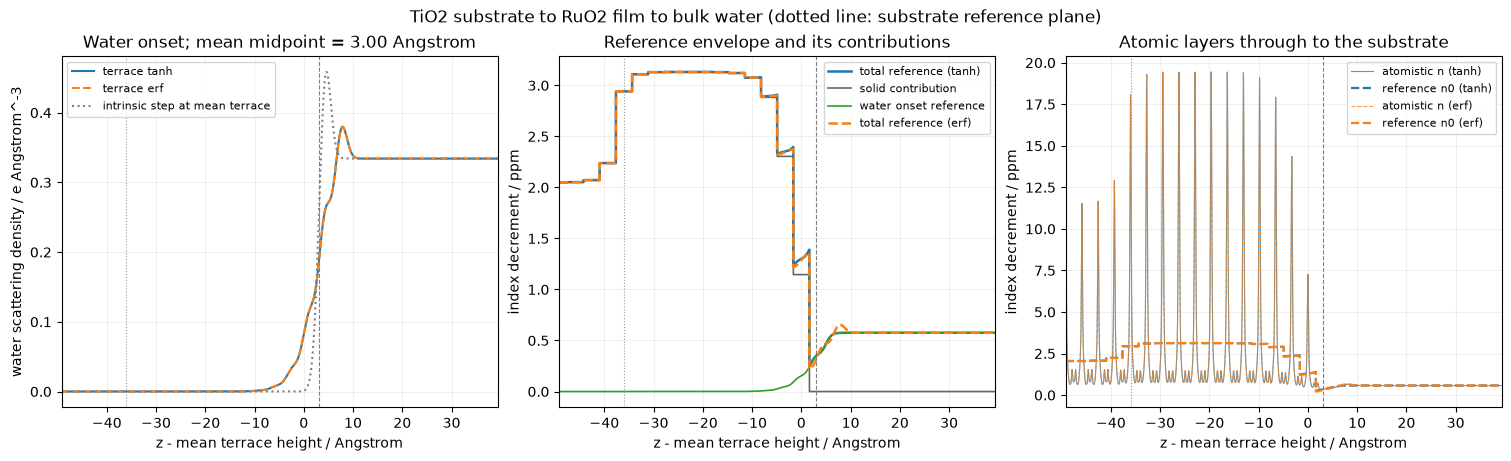

In [5]:
# Full depth range: TiO2 substrate, RuO2 layers, and the water plateau.
z_onset = np.linspace(*profile_bounds, 7001)
x_onset = z_onset - mean_height
fig_onset, onset_axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, constrained_layout=True)
for name, color in [("terrace tanh", "tab:blue"), ("terrace erf", "tab:orange")]:
    if name not in models:
        continue
    p = results[name].prepared
    spec = p.reference.continuous
    water = next(c for c in models[name].uc_surface_list if isinstance(c, PoissonSurface)).water
    rho_water = water.zDensity_G(z_onset, 0., 0.)
    scale = 2*np.pi*2.8179403262e-5/p.k0**2
    label = name.removeprefix("terrace ")
    style = "--" if label == "erf" else "-"
    onset_axes[0].plot(x_onset, rho_water.real, color=color, ls=style, label=f"terrace {label}")
    onset_axes[1].plot(x_onset, 1e6*(1-np.sqrt(spec.epsilon(z_onset)).real), color=color, ls=style, lw=1.8, label=f"total reference ({label})")
    n = 1 - scale*models[name].zDensity_G(z_onset, 0., 0.)
    onset_axes[2].plot(x_onset, 1e6*(1-n.real), color=color, ls=style, lw=0.8, alpha=0.75, label=f"atomistic n ({label})")
    onset_axes[2].plot(x_onset, 1e6*(1-np.sqrt(spec.epsilon(z_onset)).real), color=color, ls="--", lw=1.6, label=f"reference n0 ({label})")
    # Confirm the displayed right-hand interval is genuinely at bulk-water density.
    np.testing.assert_allclose(rho_water[-200:], np.full(200, water.bulk_density), rtol=1e-8, atol=1e-12)
    if label == "tanh":
        solid = spec.atomic_density(z_onset).sum(axis=0)
        onset_axes[1].plot(x_onset, 1e6*scale*solid.real, color="0.4", lw=1.2, label="solid contribution")
        onset_axes[1].plot(x_onset, 1e6*scale*spec.reference_density(z_onset)[spec.water_index].real, color="tab:green", lw=1.2, label="water onset reference")
        midpoint = water.pos_absolute + water.basis[0]*water.volume/water.uc_area
        h, prob = water._placements
        midpoint += h @ prob - mean_height
np.testing.assert_allclose(midpoint, water_onset_A, atol=1e-10)
flat = water_profile("tanh")
flat.pos_absolute = mean_height
onset_axes[0].plot(x_onset, flat.zDensity_G(z_onset, 0., 0.).real, color="0.5", ls=":", label="intrinsic step at mean terrace")
for ax in onset_axes:
    ax.axvline(midpoint, color="0.5", ls="--", lw=0.8)
    ax.axvline(-mean_height, color="0.6", ls=":", lw=0.8)
    ax.set(xlim=relative_bounds, xlabel="z - mean terrace height / Angstrom")
    ax.grid(alpha=0.18)
    ax.legend(fontsize=8)
onset_axes[0].set(title=f"Water onset; mean midpoint = {midpoint:.2f} Angstrom", ylabel="water scattering density / e Angstrom^-3")
onset_axes[1].set(title="Reference envelope and its contributions", ylabel="index decrement / ppm")
onset_axes[2].set(title="Atomic layers through to the substrate", ylabel="index decrement / ppm")
fig_onset.suptitle("TiO2 substrate to RuO2 film to bulk water (dotted line: substrate reference plane)")
plt.show()


In water: critical angle = 0.09838 deg; L = 0.03645
In vacuum: critical angle = 0.11601 deg


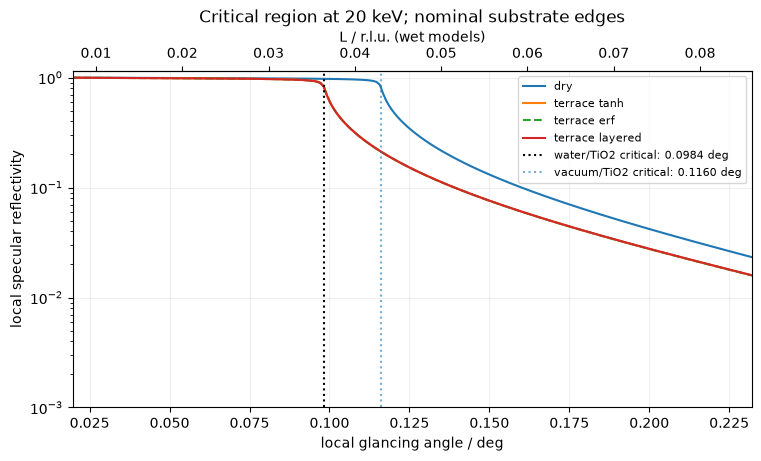

In [6]:
# Resolve the critical edge on a dense angular grid (local glancing angle).
critical = {}
for name, result in results.items():
    n = result.prepared.reference.n
    critical[name] = np.arccos(np.clip(n[-1].real / n[0].real, 0., 1.))
wet_c, dry_c = critical["terrace tanh"], critical["dry"]
angles = np.unique(np.r_[np.linspace(0.2 * wet_c, 2 * dry_c, 220), wet_c, dry_c])
fig_critical, ax = plt.subplots(figsize=(7.5, 4.5), constrained_layout=True)
for name, model in models.items():
    result = model.dwba.evaluate_from_glancing(0., 0., angles, angles)
    p = result.prepared
    origin = float(np.atleast_1d(p.field_i.z_reference)[0])
    phase = np.exp(-2j * p.k0 * p.reference.n[0] * np.sin(angles) * (common_plane-origin))
    curve = abs(result.total_amplitude * phase)**2
    assert np.all(np.isfinite(curve))
    ax.semilogy(np.rad2deg(angles), curve, "--" if name.endswith("erf") else "-", label=name)
ax.axvline(np.rad2deg(wet_c), color="black", ls=":", label=f"water/TiO2 critical: {np.rad2deg(wet_c):.4f} deg")
ax.axvline(np.rad2deg(dry_c), color="tab:blue", ls=":", alpha=0.6, label=f"vacuum/TiO2 critical: {np.rad2deg(dry_c):.4f} deg")
p = results["terrace tanh"].prepared
l_per_sine = L[0] / np.sin(p.alpha_i[0])
secondary = ax.secondary_xaxis("top", functions=(
    lambda deg: l_per_sine * np.sin(np.deg2rad(deg)),
    lambda ell: np.rad2deg(np.arcsin(np.clip(ell/l_per_sine, -1., 1.))),
))
secondary.set_xlabel("L / r.l.u. (wet models)")
ax.set(xlabel="local glancing angle / deg", ylabel="local specular reflectivity",
       xlim=np.rad2deg(angles[[0, -1]]), ylim=(1e-3, 1.15),
       title=f"Critical region at {energy/1000:g} keV; nominal substrate edges")
ax.grid(alpha=0.2)
ax.legend(fontsize=8)
print(f"In water: critical angle = {np.rad2deg(wet_c):.5f} deg; L = {l_per_sine*np.sin(wet_c):.5f}")
print(f"In vacuum: critical angle = {np.rad2deg(dry_c):.5f} deg")
plt.show()


## CTR comparison

The upper panels show $|F_{\mathrm{effective}}|^2$ at the same normalization plane in water, without separately rescaling any curve. This includes the optical reference reflection on 00L. The lower panels show the tanh/erf relative difference, omitting only points below $10^{-8}$ of the maximum erf intensity on that rod. Off-specular water has zero direct coherent amplitude; it still changes the distorted waves in the solid.

Tanh and erf now use exactly the same physical step-plus-adsorption density and molecular factors. Their difference measures the optical-reference choice and its DWBA residual, including the effective-interface and constant-medium approximations. The index decomposition above retains the existing solid-slab plus water reference; complementary smooth solid/water transitions remain unimplemented. The fitting path now avoids profile sampling and evaluates the water perturbation analytically.

00L tanh/erf: median 0.00103%, max 0.0494% (intensity floor = 0.0596)
01L dry: 0.11 s


01L terrace tanh: 0.13 s


01L terrace erf: 0.69 s
01L terrace layered: 0.14 s
01L tanh/erf: median 0.00347%, max 0.124% (intensity floor = 0.0127)


11L dry: 0.12 s
11L terrace tanh: 0.15 s


11L terrace erf: 0.66 s
11L terrace layered: 0.13 s
11L tanh/erf: median 0.00263%, max 0.0881% (intensity floor = 18.1)


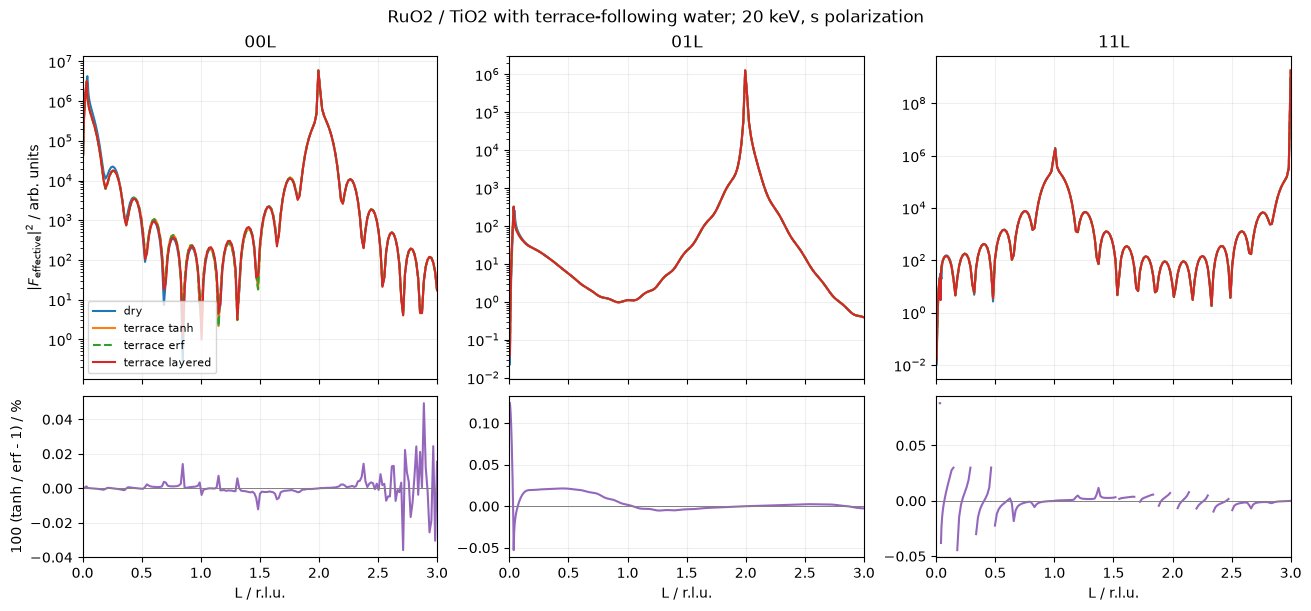

In [7]:
rods = [(0, 0), (0, 1), (1, 1)]
ctr_intensity = {}
fig_ctrs, ctr_axes = plt.subplots(2, 3, figsize=(13, 6), sharex=True,
                                 gridspec_kw={"height_ratios": [2, 1]}, constrained_layout=True)
for column, (h, k) in enumerate(rods):
    curves = {}
    for name, model in models.items():
        start = time.perf_counter()
        if (h, k) == (0, 0):
            result = results[name]
        else:
            model.dwba.set_ctr_geometry(equal_angles=True, rods=[(h, k)])
            result = model.dwba.evaluate(np.full_like(L, h), np.full_like(L, k), L)
            water_terms = [c for c in result.contributions if c.role == "water"]
            for contribution in water_terms:
                np.testing.assert_allclose(contribution.F_h, 0., atol=1e-12)
        p = result.prepared
        origin = float(np.atleast_1d(p.field_i.z_reference)[0])
        phase = np.exp(-1j*p.k0*p.reference.n[0]*(np.sin(p.alpha_i)+np.sin(p.alpha_f))*(common_plane-origin))
        curves[name] = abs(result.F_effective*phase)**2
        assert np.all(np.isfinite(curves[name]))
        style = "--" if name.endswith("erf") else "-"
        ctr_axes[0, column].semilogy(L, curves[name], style, label=name)
        if (h, k) != (0, 0):
            print(f"{h}{k}L {name}: {time.perf_counter()-start:.2f} s")
    ctr_intensity[(h, k)] = curves
    if include_confirmation:
        reference = curves["terrace erf"]
        valid = reference > reference.max()*1e-8
        relative = 100*(curves["terrace tanh"]/reference-1)
        ctr_axes[1, column].plot(L, np.where(valid, relative, np.nan), color="tab:purple")
        print(f"{h}{k}L tanh/erf: median {np.median(abs(relative[valid])):.3g}%, max {max(abs(relative[valid])):.3g}% (intensity floor = {reference.max()*1e-8:.3g})")
    ctr_axes[0, column].set(title=f"{h}{k}L")
    ctr_axes[1, column].axhline(0., color="0.5", lw=.7)
    ctr_axes[1, column].set(xlabel="L / r.l.u.", xlim=(0., 3.))
ctr_axes[0, 0].set_ylabel(r"$|F_{\mathrm{effective}}|^2$ / arb. units")
ctr_axes[1, 0].set_ylabel("100 (tanh / erf - 1) / %")
ctr_axes[0, 0].legend(fontsize=8)
for ax in ctr_axes.flat:
    ax.grid(alpha=.2)
fig_ctrs.suptitle("RuO2 / TiO2 with terrace-following water; 20 keV, s polarization")
plt.show()
